In [10]:
import osmnx as ox
import networkx as nx
import time

# 1. Configuración de seguridad para la API de OSM
ox.settings.timeout = 600       # Tiempo máximo de espera por zona
ox.settings.memory = 1000000000 # Manejo de memoria ampliado

# 2. Definición exacta de las 13 Zonas (Nombres compatibles con Nominatim OSM)
# Se utilizan las demarcaciones políticas reales que cubren tus orígenes y destinos
zonas_estudio = [
    # Orígenes (Estado de México)
    'Ecatepec de Morelos, Estado de México, México',
    'Nezahualcóyotl, Estado de México, México',
    'Chimalhuacán, Estado de México, México',
    'Tecámac, Estado de México, México',
    'Naucalpan de Juárez, Estado de México, México',
    'Tlalnepantla de Baz, Estado de México, México',
    'La Paz, Estado de México, México',
    'Chalco, Estado de México, México',
    'Atizapán de Zaragoza, Estado de México, México',
    'Cuautitlán Izcalli, Estado de México, México',
    
    # Destinos (Alcaldías centrales y polos económicos en CDMX)
    'Cuauhtémoc, Ciudad de México, México',       # Cubre Centro CDMX
    'Miguel Hidalgo, Ciudad de México, México',   # Cubre Reforma / Polanco
    'Álvaro Obregón, Ciudad de México, México'    # Cubre parte de Santa Fe / Observatorio
]

print("Iniciando descarga por bloques. Esto puede tomar varios minutos...\n")

# 3. Inicializar un grafo vacío donde se fusionarán todas las zonas
G_total = nx.MultiDiGraph()

# 4. Motor de Descarga y Fusión
for zona in zonas_estudio:
    print(f"Descargando red peatonal de: {zona}...")
    try:
        # Descargar exclusivamente las calles de esta zona
        G_local = ox.graph_from_place(zona, network_type='walk', simplify=True)
        
        # Fusionar el grafo local con el grafo total maestro
        G_total = nx.compose(G_total, G_local)
        print(f"✓ Éxito. Nodos actuales en la red: {len(G_total.nodes)}")
        
        # Pausa de 5 segundos para no saturar la API (Evita el Error 502)
        time.sleep(5)
        
    except Exception as e:
        print(f"✗ Error al descargar {zona}. Saltando... Detalles: {e}")

# 5. Imputar tiempos de caminata (1.25 m/s) al grafo fusionado
print("\nCalculando tiempos de recorrido para toda la red combinada...")
for u, v, k, data in G_total.edges(keys=True, data=True):
    distancia_m = data.get('length', 0)
    data['travel_time_min'] = (distancia_m / 1.25) / 60.0

# 6. Guardar el resultado final para uso offline
archivo_salida = "red_peatonal_13_zonas.graphml"
ox.save_graphml(G_total, filepath=archivo_salida)

print(f"\n¡Proceso finalizado! Grafo unificado guardado en '{archivo_salida}'.")
print(f"Total final: {len(G_total.nodes):,} nodos y {len(G_total.edges):,} aristas.")

Iniciando descarga por bloques. Esto puede tomar varios minutos...

Descargando red peatonal de: Ecatepec de Morelos, Estado de México, México...
✓ Éxito. Nodos actuales en la red: 36318
Descargando red peatonal de: Nezahualcóyotl, Estado de México, México...
✓ Éxito. Nodos actuales en la red: 43544
Descargando red peatonal de: Chimalhuacán, Estado de México, México...
✓ Éxito. Nodos actuales en la red: 57301
Descargando red peatonal de: Tecámac, Estado de México, México...
✓ Éxito. Nodos actuales en la red: 76904
Descargando red peatonal de: Naucalpan de Juárez, Estado de México, México...
✓ Éxito. Nodos actuales en la red: 97426
Descargando red peatonal de: Tlalnepantla de Baz, Estado de México, México...
✓ Éxito. Nodos actuales en la red: 110252
Descargando red peatonal de: La Paz, Estado de México, México...
✓ Éxito. Nodos actuales en la red: 118641
Descargando red peatonal de: Chalco, Estado de México, México...
✓ Éxito. Nodos actuales en la red: 133262
Descargando red peatonal de

In [21]:
import osmnx as ox
import networkx as nx

# 1. Cargar el grafo maestro que ya tiene las 12 zonas exitosas
G_total = ox.load_graphml("red_peatonal_13_zonas.graphml")
print(f"Nodos iniciales: {len(G_total.nodes)}")

# 2. Descargar Izcalli usando coordenadas centrales y un radio de 6 km
# Coordenadas: 19.6438° N, 99.2155° W
print("Descargando red de Cuautitlán Izcalli por radio geográfico...")
G_izcalli = ox.graph_from_point((19.6438, -99.2155), dist=6000, network_type='walk', simplify=True)

# 3. Imputar el tiempo de caminata a las nuevas calles de Izcalli
for u, v, k, data in G_izcalli.edges(keys=True, data=True):
    data['travel_time_min'] = (data.get('length', 0) / 1.25) / 60.0

# 4. Fusionar el grafo de Izcalli con el grafo maestro
G_total = nx.compose(G_total, G_izcalli)

# 5. Sobrescribir el archivo final actualizado
ox.save_graphml(G_total, filepath="red_peatonal_13_zonas.graphml")

print(f"¡Izcalli integrado con éxito! Nodos totales ahora: {len(G_total.nodes)}")

Nodos iniciales: 306526
Descargando red de Cuautitlán Izcalli por radio geográfico...
¡Izcalli integrado con éxito! Nodos totales ahora: 333678


In [12]:
import geopandas as gpd
import pandas as pd

# 1. Cargar las capas de AGEBs (Sustituye por las rutas exactas donde guardaste los archivos .shp)
print("Cargando AGEBs de CDMX y Estado de México...")
agebs_cdmx = gpd.read_file("sigma-cronomx v1/09_ciudaddemexico/conjunto_de_datos/09a.shp")
agebs_edomex = gpd.read_file("sigma-cronomx v1/15_mexico/conjunto_de_datos/15a.shp")

# 2. Unir ambos mapas vectoriales en un solo GeoDataFrame maestro
agebs_zmvm = pd.concat([agebs_cdmx, agebs_edomex], ignore_index=True)
agebs_zmvm = gpd.GeoDataFrame(agebs_zmvm, crs=agebs_cdmx.crs)

print(f"Total de AGEBs cargados en el área combinada: {len(agebs_zmvm):,}")
print(agebs_zmvm.columns)
# 3. Filtrar únicamente los municipios y alcaldías de tu estudio
# (Asegúrate de revisar la columna que contiene los nombres, habitualmente 'NOMGEO')
# Diccionario de claves del INEGI (Entidad + Municipio) hacia los nombres de tu estudio
# 15 = Estado de México, 09 = CDMX
claves_inegi = {
    '15033': 'Ecatepec de Morelos',
    '15058': 'Nezahualcóyotl',
    '15031': 'Chimalhuacán',
    '15081': 'Tecámac',
    '15057': 'Naucalpan de Juárez',
    '15104': 'Tlalnepantla de Baz',
    '15070': 'La Paz',
    '15025': 'Chalco',
    '15013': 'Atizapán de Zaragoza',
    '15121': 'Cuautitlán Izcalli',
    '09015': 'Cuauhtémoc',
    '09016': 'Miguel Hidalgo',
    '09010': 'Álvaro Obregón'
}

# 1. Crear una clave única combinando el código de Estado y Municipio
agebs_zmvm['CLAVE_UNICA'] = agebs_zmvm['CVE_ENT'] + agebs_zmvm['CVE_MUN']

# 2. Generar la columna 'NOMGEO' mapeando las claves con los nombres de tu diccionario
agebs_zmvm['NOMGEO'] = agebs_zmvm['CLAVE_UNICA'].map(claves_inegi)

# 3. Filtrar el mapa quedándote solo con las filas que sí encontraron un nombre en el diccionario
agebs_estudio = agebs_zmvm.dropna(subset=['NOMGEO']).copy()

# A partir de aquí tu código original funcionará perfectamente
# Proyectar a metros (UTM 14N) para obtener los centroides y regresar a GPS
agebs_estudio = agebs_estudio.to_crs(epsg=32614)
agebs_estudio['centroide'] = agebs_estudio.geometry.centroid
# ... resto de tu código

# 4. Proyectar a metros (UTM 14N) para obtener los centroides y regresar a GPS
agebs_estudio = agebs_estudio.to_crs(epsg=32614)
agebs_estudio['centroide'] = agebs_estudio.geometry.centroid
agebs_estudio = agebs_estudio.to_crs(epsg=4326)
agebs_estudio['centroide'] = agebs_estudio['centroide'].to_crs(epsg=4326)

# Coordenadas exactas para cruzar con OSMnx
agebs_estudio['lon'] = agebs_estudio['centroide'].x
agebs_estudio['lat'] = agebs_estudio['centroide'].y

print(f"AGEBs filtrados listos para procesar la primera milla: {len(agebs_estudio):,}")

Cargando AGEBs de CDMX y Estado de México...
Total de AGEBs cargados en el área combinada: 6,805
Index(['CVEGEO', 'CVE_ENT', 'CVE_MUN', 'CVE_LOC', 'CVE_AGEB', 'geometry'], dtype='str')
AGEBs filtrados listos para procesar la primera milla: 2,312


In [21]:
import geopandas as gpd
import pandas as pd
import networkx as nx
import numpy as np
import osmnx as ox

print("1. Cargando Datos de Transporte Masivo (GTFS) y Marginación (CONAPO)...")
ruta_limpia = "sigma-cronomx v1/backend/gtfs_limpio/"
stop_times_df = pd.read_csv(ruta_limpia + "stop_times.csv")
stops_df = pd.read_csv(ruta_limpia + "stops.csv")
conapo_df = pd.read_csv(ruta_limpia + "conapo_im_2020.csv") 

# Normalización Min-Max del Índice de Marginación (0 a 1)
conapo_df['municipio'] = conapo_df['municipio'].str.strip()
min_im, max_im = conapo_df['im_raw'].min(), conapo_df['im_raw'].max()
conapo_df['im_normalizado'] = (conapo_df['im_raw'] - min_im) / (max_im - min_im)

def tiempo_a_minutos(hora_str):
    if pd.isna(hora_str): return np.nan
    h, m, s = map(int, str(hora_str).split(':'))
    return (h * 60) + m + (s / 60.0)

# 2. Frecuencias de Espera en GTFS (Headway / 2)
stop_times_df['llegada_min'] = stop_times_df['arrival_time'].apply(tiempo_a_minutos)
stop_times_df = stop_times_df.sort_values(by=['stop_id', 'llegada_min'])
stop_times_df['siguiente_llegada'] = stop_times_df.groupby('stop_id')['llegada_min'].shift(-1)
stop_times_df['headway'] = stop_times_df['siguiente_llegada'] - stop_times_df['llegada_min']

headways_validos = stop_times_df[(stop_times_df['headway'] > 1) & (stop_times_df['headway'] <= 30)]
espera_promedio_estacion = (headways_validos.groupby('stop_id')['headway'].mean() / 2.0).to_dict()
ESPERA_DEFAULT = 4.0

print("2. Construyendo Red GTFS con Penalización de Transbordos Reales...")
stop_times_df = stop_times_df.sort_values(by=['trip_id', 'stop_sequence'])
stop_times_df['siguiente_parada'] = stop_times_df.groupby('trip_id')['stop_id'].shift(-1)
stop_times_df['tiempo_siguiente_parada'] = stop_times_df.groupby('trip_id')['llegada_min'].shift(-1)
stop_times_df['tiempo_tramo'] = stop_times_df['tiempo_siguiente_parada'] - stop_times_df['llegada_min']

edges_df = stop_times_df.dropna(subset=['siguiente_parada', 'tiempo_tramo']).copy()
edges_df = edges_df[edges_df['tiempo_tramo'] > 0]

G = nx.DiGraph()
for _, row in edges_df.iterrows():
    G.add_edge(row['stop_id'], row['siguiente_parada'], weight=row['tiempo_tramo'])

# Transbordos con penalizaciones realistas
transbordos_reales = {
    'LA RAZA': 12.0, 'PANTITLAN': 10.0, 'CONSTITUCION DE 1917': 8.0,
    'INDIO VERDES': 8.0, 'EL ROSARIO': 8.0, 'BALDERAS': 4.0
}

for nombre_estacion, grupo in stops_df.groupby('stop_name'):
    nodos = grupo['stop_id'].tolist()
    if len(nodos) > 1:
        tiempo_transbordo = transbordos_reales.get(nombre_estacion.upper(), 5.0)
        for i in range(len(nodos)):
            for j in range(i + 1, len(nodos)):
                G.add_edge(nodos[i], nodos[j], weight=tiempo_transbordo)
                G.add_edge(nodos[j], nodos[i], weight=tiempo_transbordo)

print("3. Cargando Red Peatonal y Vial (OSMnx)...")
G_walk = ox.load_graphml("red_peatonal_13_zonas.graphml")

print("4. Evaluando 2,312 AGEBs con Capa de Transporte Concesionado (Combi/Microbús)...")
origenes = {
    'Ecatepec de Morelos': 'B_0200LB-CIUDADAZTECA', 'Nezahualcóyotl': 'B_0200LB-NEZAHUALCO',
    'Chimalhuacán': 'B_0200LA-PANTITLAN', 'Tecámac': 'B_0200L3-INDIOSVERD',
    'Naucalpan de Juárez': 'B_0200L2-CUATROCAMIN', 'Tlalnepantla de Baz': 'B_0200L7-ELROSARIO',
    'La Paz': 'B_0200LA-LAPAZ', 'Chalco': 'B_0200LA-LAPAZ',
    'Atizapán de Zaragoza': 'B_0200L2-CUATROCAMIN', 'Cuautitlán Izcalli': 'B_0200L7-ELROSARIO'
}

destinos_empleo = {
    'Centro CDMX': 'B_0200L2-PINOSUAREZ',
    'Reforma/Polanco': 'B_0200L7-POLANCO',
    'Santa Fe (Observatorio)': 'B_0200L1-OBSERVATORIO'
}

# Parámetros Operativos del Transporte Concesionado en ZMVM
VELOCIDAD_PEATONAL_MS = 1.25          # 4.5 km/h a pie
VELOCIDAD_CONCESIONADO_KMH = 15.0     # 15 km/h combi con paradas y tráfico
VELOCIDAD_CONCESIONADO_MS = (VELOCIDAD_CONCESIONADO_KMH * 1000) / 3600.0
FRICCION_ABORDAJE_COMBI_MIN = 6.0    # Caminata corta a la base + tiempo de llenado/espera de la unidad

resultados_ageb = []

for index, fila in agebs_estudio.iterrows():
    municipio = fila['NOMGEO']
    if municipio not in origenes: continue
        
    id_estacion = origenes[municipio]
    datos_estacion = stops_df[stops_df['stop_id'] == id_estacion].iloc[0]
    
    nodo_origen = ox.distance.nearest_nodes(G_walk, X=fila['lon'], Y=fila['lat'])
    nodo_estacion = ox.distance.nearest_nodes(G_walk, X=datos_estacion['stop_lon'], Y=datos_estacion['stop_lat'])
    
    try:
        distancia_metros = nx.shortest_path_length(G_walk, source=nodo_origen, target=nodo_estacion, weight='length')
    except nx.NetworkXNoPath:
        # Si la red vial está desconectada, usar la fórmula de distancia Haversine manual
        from math import radians, cos, sin, asin, sqrt
        lon1, lat1 = map(radians, [fila['lon'], fila['lat']])
        lon2, lat2 = map(radians, [datos_estacion['stop_lon'], datos_estacion['stop_lat']])
        dlon = lon2 - lon1
        dlat = lat2 - lat1
        a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
        c = 2 * asin(sqrt(a))
        radio_tierra_m = 6371000
        distancia_metros = c * radio_tierra_m
    
    # Lógica de Elección de Modo de Alimentación (Caminata vs. Combi)
    if distancia_metros <= 800:
        # Tramo caminable directamente (< 800m)
        tiempo_alimentacion = (distancia_metros / VELOCIDAD_PEATONAL_MS) / 60.0
        modo_usado = "Caminata"
    else:
        # Trayecto en transporte concesionado (combi/microbús)
        tiempo_rodadura_combi = (distancia_metros / VELOCIDAD_CONCESIONADO_MS) / 60.0
        tiempo_alimentacion = tiempo_rodadura_combi + FRICCION_ABORDAJE_COMBI_MIN
        modo_usado = "Transporte Concesionado"
        
    resultados_ageb.append({
        'Municipio': municipio, 
        'Tiempo_Alimentacion': tiempo_alimentacion,
        'Distancia_m': distancia_metros
    })

# Promediar tiempo de acceso/alimentación por municipio
alimentacion_promedio_df = pd.DataFrame(resultados_ageb).groupby('Municipio')['Tiempo_Alimentacion'].mean().reset_index()

print("5. Integrando Tiempos Totales y Recalculando IPT Compuesto...")
resultados_finales = []

for index, fila in alimentacion_promedio_df.iterrows():
    municipio = fila['Municipio']
    origen_id = origenes[municipio]
    tiempo_alimentacion_prom = fila['Tiempo_Alimentacion']
    
    # Tiempo de espera por frecuencia en la estación masiva de acceso
    tiempo_espera_masivo = espera_promedio_estacion.get(origen_id, ESPERA_DEFAULT)
    
    # Marginación CONAPO
    try:
        im_val = conapo_df.loc[conapo_df['municipio'] == municipio, 'im_normalizado'].values[0]
    except IndexError:
        im_val = 0.5
        
    # Tiempo a bordo de la red masiva (GTFS)
    tiempos_hacia_destinos = []
    for dest_nombre, dest_id in destinos_empleo.items():
        try:
            t = nx.shortest_path_length(G, source=origen_id, target=dest_id, weight='weight')
            tiempos_hacia_destinos.append(t)
        except nx.NetworkXNoPath:
            continue
            
    tiempo_gtfs_minimo = min(tiempos_hacia_destinos) if tiempos_hacia_destinos else float('inf')
    
    # Tiempo Total = Alimentación (Combi/Caminata) + Espera en Andén + Viaje Masivo (GTFS)
    tiempo_total = tiempo_alimentacion_prom + tiempo_espera_masivo + tiempo_gtfs_minimo
    
    # Ecuación IPT CronoMX (decay threshold 120 min)
    acc_relativa = max(0, 1 - (tiempo_total / 120.0)) if tiempo_total != float('inf') else 0.0
    ipt_comp = (1 - acc_relativa) * (1 + im_val)
    
    resultados_finales.append({
        'Municipio': municipio,
        'Alimentación/Combi (min)': round(tiempo_alimentacion_prom, 1),
        'Espera Andén (min)': round(tiempo_espera_masivo, 1),
        'Viaje GTFS (min)': round(tiempo_gtfs_minimo, 1),
        'Tiempo Total Real (min)': round(tiempo_total, 1),
        'IM_Norm': round(im_val, 3),
        'Acc_Relativa': round(acc_relativa, 3),
        'IPT_comp': round(ipt_comp, 3)
    })

df_resultados = pd.DataFrame(resultados_finales).sort_values(by='IPT_comp', ascending=False)

# Renderizado final estilizado
tabla_estilizada = df_resultados.style\
    .background_gradient(cmap='Reds', subset=['IPT_comp'])\
    .format({
        'Alimentación/Combi (min)': '{:.1f} min',
        'Espera Andén (min)': '{:.1f} min',
        'Viaje GTFS (min)': '{:.1f} min',
        'Tiempo Total Real (min)': '{:.1f} min',
        'IM_Norm': '{:.3f}',
        'Acc_Relativa': '{:.1%}',
        'IPT_comp': '{:.3f}'
    })\
    .set_caption("Ranking IPT Ajustado: Transporte Concesionado + Red Masiva (ZMVM)")

tabla_estilizada

1. Cargando Datos de Transporte Masivo (GTFS) y Marginación (CONAPO)...
2. Construyendo Red GTFS con Penalización de Transbordos Reales...
3. Cargando Red Peatonal y Vial (OSMnx)...
4. Evaluando 2,312 AGEBs con Capa de Transporte Concesionado (Combi/Microbús)...
5. Integrando Tiempos Totales y Recalculando IPT Compuesto...


,Municipio,Alimentación/Combi (min),Espera Andén (min),Viaje GTFS (min),Tiempo Total Real (min),IM_Norm,Acc_Relativa,IPT_comp
8,Tecámac,109.0 min,4.0 min,23.4 min,136.4 min,0.926,0.0%,1.926
7,Nezahualcóyotl,79.8 min,5.2 min,30.2 min,115.2 min,0.864,4.0%,1.789
1,Chalco,61.5 min,12.2 min,50.3 min,124.0 min,0.724,0.0%,1.724
3,Cuautitlán Izcalli,71.4 min,13.8 min,14.2 min,99.3 min,0.972,17.3%,1.632
0,Atizapán de Zaragoza,80.2 min,4.0 min,15.9 min,100.2 min,0.920,16.5%,1.603
9,Tlalnepantla de Baz,65.6 min,13.8 min,14.2 min,93.5 min,0.918,22.1%,1.495
2,Chimalhuacán,57.7 min,12.2 min,25.8 min,95.7 min,0.721,20.2%,1.373
4,Ecatepec de Morelos,36.3 min,4.0 min,44.2 min,84.4 min,0.872,29.6%,1.317
5,La Paz,22.0 min,12.2 min,50.3 min,84.5 min,0.688,29.6%,1.189
6,Naucalpan de Juárez,32.3 min,4.0 min,15.9 min,52.2 min,0.872,56.5%,0.815


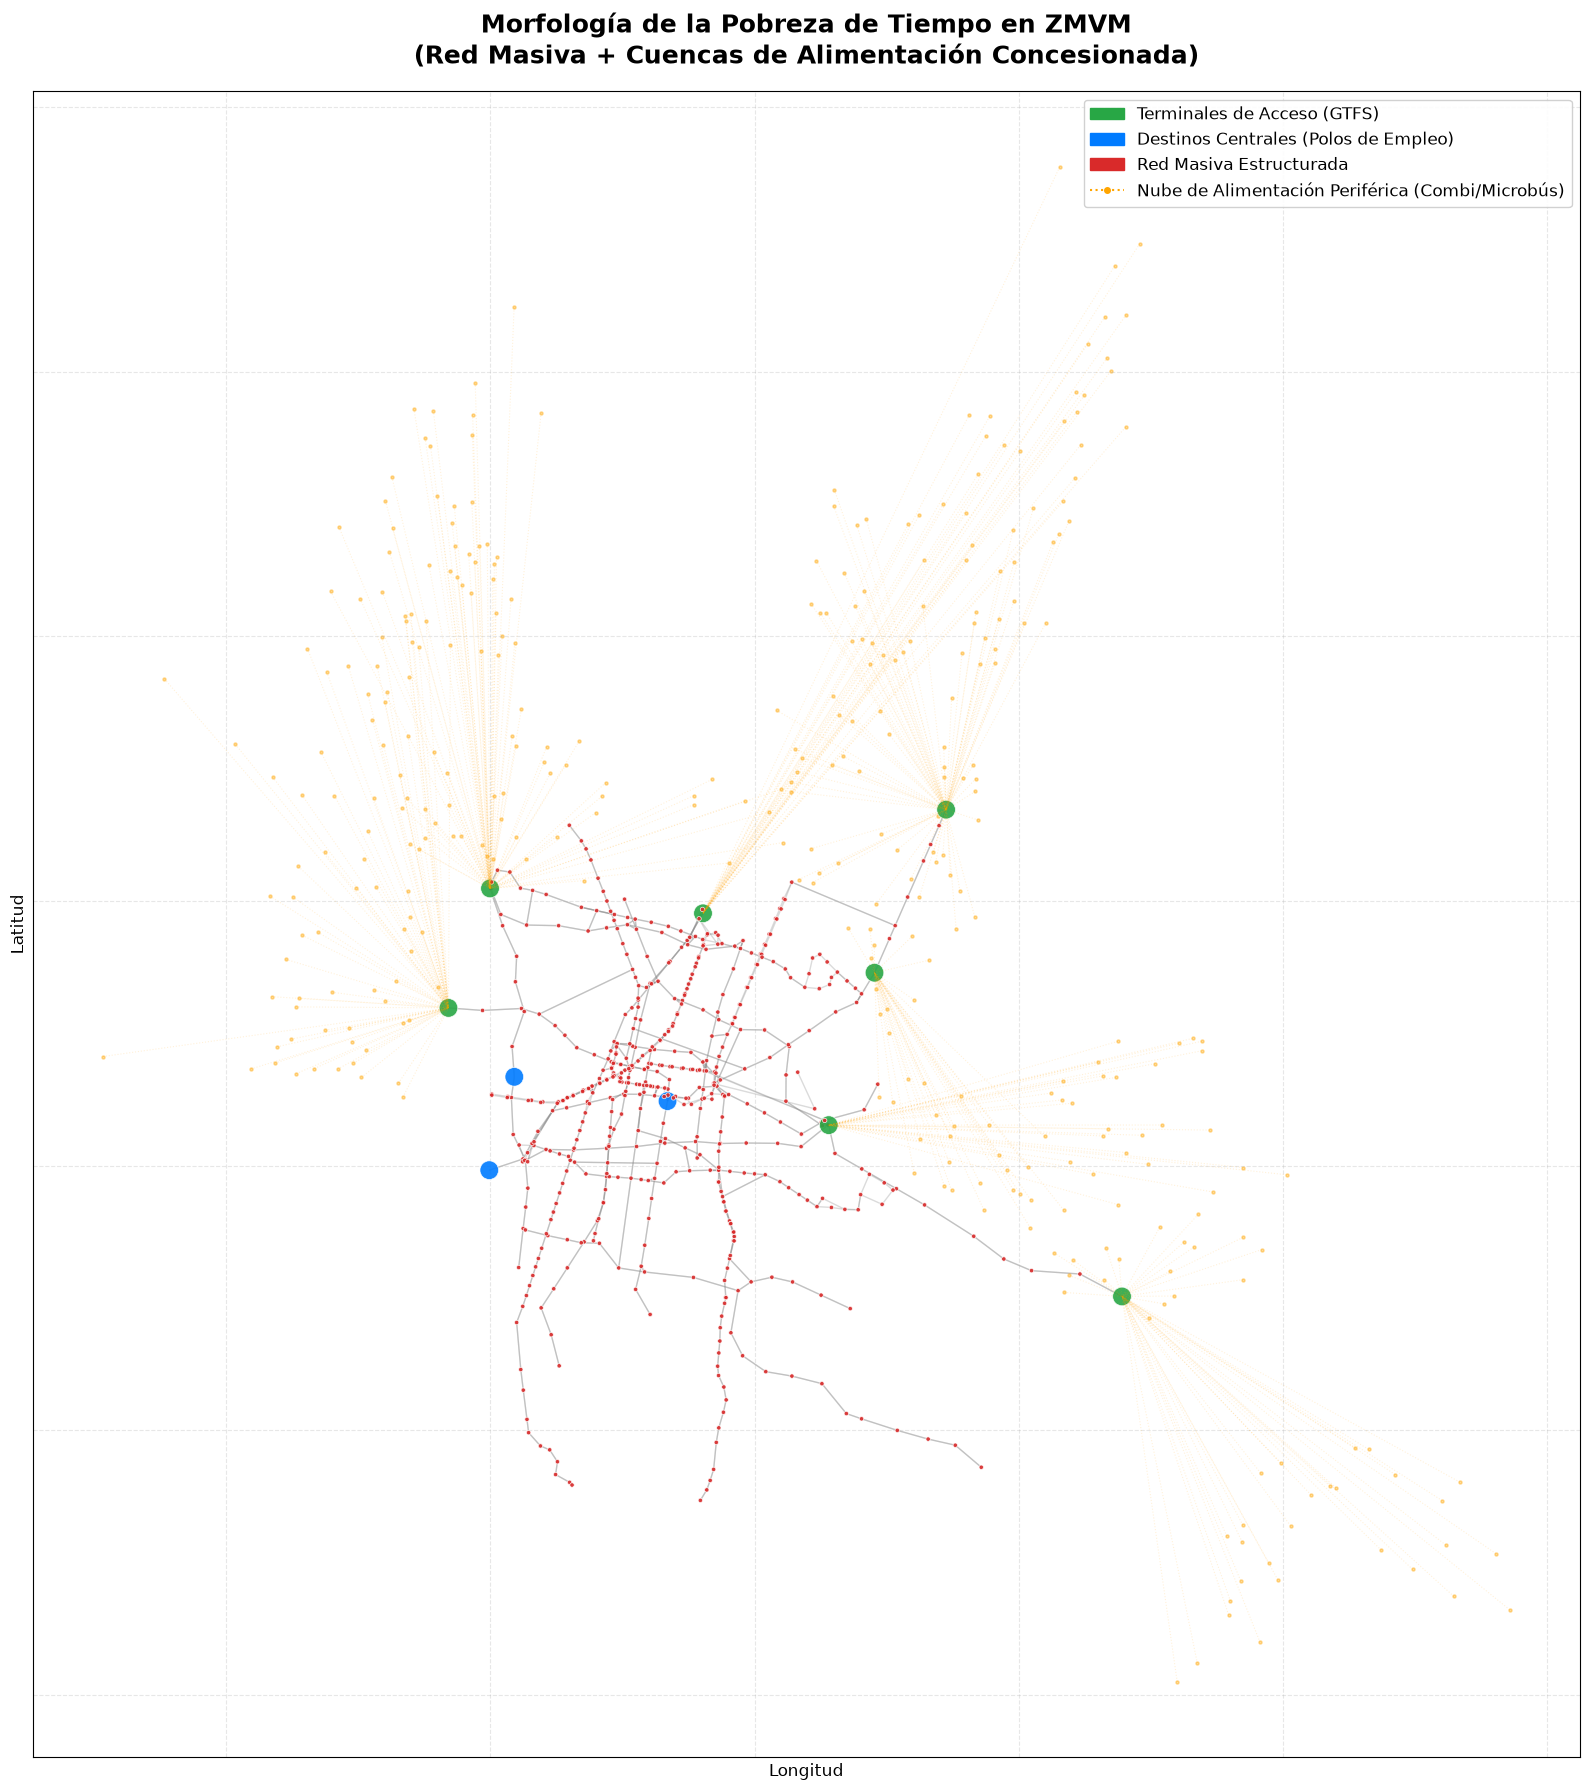

In [23]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import networkx as nx
import pandas as pd

# 1. Extraer coordenadas espaciales de la red GTFS
posiciones_reales = {}
for _, fila in stops_df.iterrows():
    if pd.notna(fila['stop_lat']) and pd.notna(fila['stop_lon']):
        posiciones_reales[fila['stop_id']] = (fila['stop_lon'], fila['stop_lat'])

G_geo = G.subgraph([n for n in G.nodes() if n in posiciones_reales])

ids_destinos = list(destinos_empleo.values())
ids_origenes = list(set(origenes.values()))

colores = []
tamanos = []
for nodo in G_geo.nodes():
    if nodo in ids_origenes:
        colores.append('#28a745')     # Verde (Estaciones de abordaje)
        tamanos.append(180)           
    elif nodo in ids_destinos:
        colores.append('#007bff')     # Azul (Polos de empleo)
        tamanos.append(180)           
    else:
        colores.append('#d92a2a')     # Rojo (Nodos de tránsito GTFS)
        tamanos.append(10)            

plt.figure(figsize=(16, 18), facecolor='white')

# 2. Dibujar la Red Masiva (GTFS)
nx.draw_networkx_edges(G_geo, posiciones_reales, edge_color='#888888', alpha=0.3, arrows=False)
nx.draw_networkx_nodes(G_geo, posiciones_reales, node_color=colores, node_size=tamanos, alpha=0.9, edgecolors='white', linewidths=0.5)

# 3. Dibujar la Nube de Alimentación Periférica (AGEBs -> Combi -> Estación)
# Dibujaremos un muestreo (ej. 1 de cada 5 AGEBs para no saturar el mapa visualmente)
agebs_muestra = agebs_estudio.iloc[::5] 

for index, fila in agebs_muestra.iterrows():
    municipio = fila['NOMGEO']
    if municipio in origenes:
        id_estacion = origenes[municipio]
        if id_estacion in posiciones_reales:
            lon_estacion, lat_estacion = posiciones_reales[id_estacion]
            lon_ageb, lat_ageb = fila['lon'], fila['lat']
            
            # Dibujar línea de conexión (Ruta alimentadora)
            plt.plot([lon_ageb, lon_estacion], [lat_ageb, lat_estacion], color='orange', alpha=0.15, linewidth=0.8, linestyle=':')
            # Dibujar el barrio (AGEB)
            plt.scatter(lon_ageb, lat_ageb, color='orange', s=5, alpha=0.4)

# 4. Leyendas y formato
leyenda_origen = mpatches.Patch(color='#28a745', label='Terminales de Acceso (GTFS)')
leyenda_destino = mpatches.Patch(color='#007bff', label='Destinos Centrales (Polos de Empleo)')
leyenda_red = mpatches.Patch(color='#d92a2a', label='Red Masiva Estructurada')
leyenda_combi = mlines.Line2D([], [], color='orange', marker='o', linestyle=':', markersize=4, label='Nube de Alimentación Periférica (Combi/Microbús)')

plt.legend(handles=[leyenda_origen, leyenda_destino, leyenda_red, leyenda_combi], loc='upper right', fontsize=12, framealpha=0.9)

plt.title("Morfología de la Pobreza de Tiempo en ZMVM\n(Red Masiva + Cuencas de Alimentación Concesionada)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("Longitud", fontsize=12)
plt.ylabel("Latitud", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.axis('on') 

plt.tight_layout()


plt.savefig("grafo_red_cronomx.png", dpi=300, bbox_inches='tight')

plt.show()